<a href="https://colab.research.google.com/github/damlamengus/HAM10000-Skin-Lesion-Classification/blob/main/notebooks/01_veri_kesfi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("GPU kullanılabilir:", torch.cuda.is_available())
print("Proje ortamı hazır!")


Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
PyTorch: 2.14.1+cu130
GPU kullanılabilir: True
Proje ortamı hazır!


In [1]:

import pandas as pd

df = pd.read_csv("/content/HAM10000_metadata.csv", sep=",")

print("Veri setinin boyutu:", df.shape)

print("\nSütun isimleri:")
print(df.columns.tolist())

print("\nİlk 5 kayıt:")
display(df.head())

print("\nEksik değer sayıları:")
print(df.isnull().sum())

print("\nSınıf dağılımı:")
print(df["dx"].value_counts())

print("\nBenzersiz lezyon sayısı:")
print(df["lesion_id"].nunique())


Veri setinin boyutu: (10015, 7)

Sütun isimleri:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

İlk 5 kayıt:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Eksik değer sayıları:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

Sınıf dağılımı:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Benzersiz lezyon sayısı:
7470


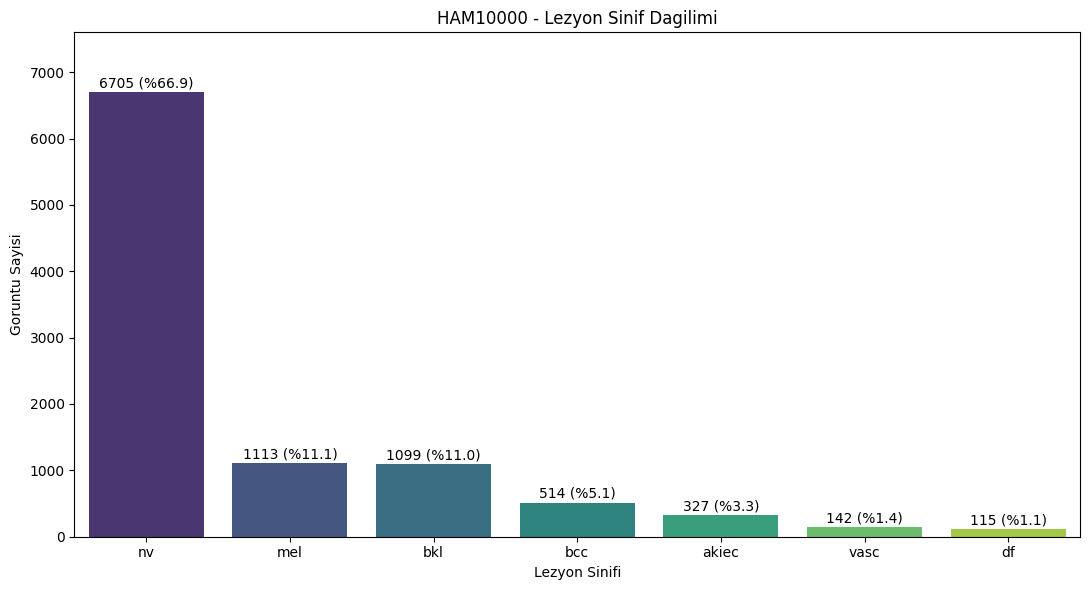

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

sinif_adlari = {
    "nv": "Melanositik Nevus",
    "mel": "Melanom",
    "bkl": "Benign Keratoz",
    "bcc": "Bazal Hucreli Karsinom",
    "akiec": "Aktinik Keratoz",
    "vasc": "Vaskuler Lezyon",
    "df": "Dermatofibrom"
}

sinif_sayilari = df["dx"].value_counts()
sinif_yuzdeleri = df["dx"].value_counts(normalize=True) * 100

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=sinif_sayilari.index,
    y=sinif_sayilari.values,
    hue=sinif_sayilari.index,
    palette="viridis",
    legend=False
)

for i, (adet, yuzde) in enumerate(
    zip(sinif_sayilari.values, sinif_yuzdeleri.values)
):
    ax.text(
        i, adet + 70,
        f"{adet} (%{yuzde:.1f})",
        ha="center",
        fontsize=10
    )

plt.title("HAM10000 - Lezyon Sinif Dagilimi")
plt.xlabel("Lezyon Sinifi")
plt.ylabel("Goruntu Sayisi")
plt.ylim(0, 7600)
plt.tight_layout()
plt.savefig("sinif_dagilimi.png", dpi=300)
plt.show()


In [3]:

lezyon_tekrarlari = df.groupby("lesion_id").size()

print("Toplam goruntu:", len(df))
print("Benzersiz lezyon:", df["lesion_id"].nunique())

print(
    "Birden fazla goruntusu olan lezyon sayisi:",
    (lezyon_tekrarlari > 1).sum()
)

print(
    "Tekrarlanan lezyonlara ait toplam goruntu:",
    lezyon_tekrarlari[lezyon_tekrarlari > 1].sum()
)

print(
    "Bir lezyona ait maksimum goruntu sayisi:",
    lezyon_tekrarlari.max()
)

print("\nLezyon basina goruntu sayisi dagilimi:")
print(lezyon_tekrarlari.value_counts().sort_index())


Toplam goruntu: 10015
Benzersiz lezyon: 7470
Birden fazla goruntusu olan lezyon sayisi: 1956
Tekrarlanan lezyonlara ait toplam goruntu: 4501
Bir lezyona ait maksimum goruntu sayisi: 6

Lezyon basina goruntu sayisi dagilimi:
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64


In [4]:

from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# 1. Egitim (%70) ve gecici (%30) ayirimi
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(df, groups=df["lesion_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# 2. Gecici veriyi ayirma validation ve test olarak
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["lesion_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# 3. Lezyon cakismalarini kontrol etme
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# 4. Veri boyutlarini yazdirma
for isim, veri in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{isim}: {len(veri)} goruntu, "
        f"{veri['lesion_id'].nunique()} lezyon, "
        f"%{len(veri)/len(df)*100:.2f}"
    )

print("\nLezyon bazli veri sizintisi: YOK")

# 5. Sinif dagilimlarini karsilastirma
dagilim = pd.DataFrame({
    "Tum veri": df["dx"].value_counts(normalize=True),
    "Train": train_df["dx"].value_counts(normalize=True),
    "Validation": val_df["dx"].value_counts(normalize=True),
    "Test": test_df["dx"].value_counts(normalize=True)
}).fillna(0) * 100

print("\nSinif dagilimlari (%):")
display(dagilim.round(2))


Train: 7002 goruntu, 5229 lezyon, %69.92
Validation: 1519 goruntu, 1120 lezyon, %15.17
Test: 1494 goruntu, 1121 lezyon, %14.92

Lezyon bazli veri sizintisi: YOK

Sinif dagilimlari (%):


,Tum veri,Train,Validation,Test
dx,,,,
akiec,3.27,2.96,3.75,4.22
bcc,5.13,5.44,4.28,4.55
bkl,10.97,10.58,13.56,10.17
df,1.15,1.27,1.25,0.47
mel,11.11,11.00,10.27,12.52
nv,66.95,67.38,65.24,66.67
vasc,1.42,1.37,1.65,1.41


Yas istatistikleri:


,age
count,9958.000000
mean,51.863828
std,16.968614
min,0.000000
25%,40.000000
50%,50.000000
75%,65.000000
max,85.000000



Siniflara gore yas istatistikleri:


,count,mean,median,std,min,max
dx,,,,,,
akiec,327,66.53,70.0,11.48,30.0,85.0
bcc,514,66.83,70.0,13.66,20.0,85.0
bkl,1089,64.28,65.0,14.12,0.0,85.0
df,115,53.04,50.0,13.55,25.0,80.0
mel,1111,60.68,60.0,15.19,5.0,85.0
nv,6660,46.48,45.0,15.18,0.0,85.0
vasc,142,51.37,55.0,21.64,0.0,85.0



Cinsiyet dagilimi:


,count
sex,
male,5406
female,4552
unknown,57



Lokalizasyon dagilimi:


,count
localization,
back,2192
lower extremity,2077
trunk,1404
upper extremity,1118
abdomen,1022
face,745
chest,407
foot,319
unknown,234


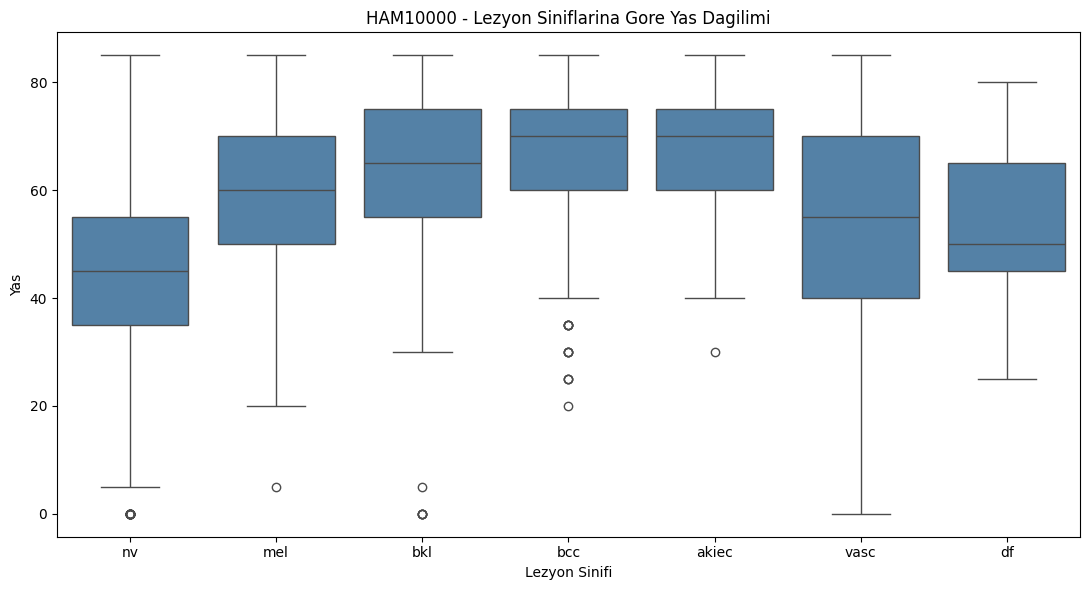

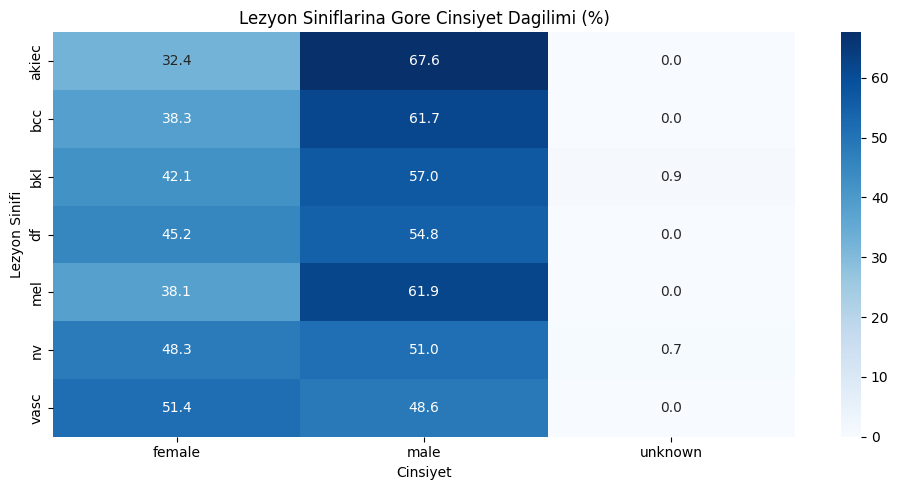

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Yas analizi
print("Yas istatistikleri:")
display(df["age"].describe())

print("\nSiniflara gore yas istatistikleri:")
display(
    df.groupby("dx")["age"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(2)
)

# 2. Cinsiyet dagilimi
print("\nCinsiyet dagilimi:")
display(df["sex"].value_counts(dropna=False))

# 3. Anatomik lokalizasyon
print("\nLokalizasyon dagilimi:")
display(df["localization"].value_counts(dropna=False))

# 4. Siniflara gore yas grafigi
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df,
    x="dx",
    y="age",
    order=df["dx"].value_counts().index,
    color="steelblue"
)
plt.title("HAM10000 - Lezyon Siniflarina Gore Yas Dagilimi")
plt.xlabel("Lezyon Sinifi")
plt.ylabel("Yas")
plt.tight_layout()
plt.savefig("yas_dagilimi.png", dpi=300)
plt.show()

# 5. Cinsiyet ve lezyon sinifi iliskisi
cinsiyet_tablo = pd.crosstab(
    df["dx"],
    df["sex"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 5))
sns.heatmap(
    cinsiyet_tablo,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)
plt.title("Lezyon Siniflarina Gore Cinsiyet Dagilimi (%)")
plt.xlabel("Cinsiyet")
plt.ylabel("Lezyon Sinifi")
plt.tight_layout()
plt.savefig("cinsiyet_sinif_iliskisi.png", dpi=300)
plt.show()


dx - Tutarsiz lezyon sayisi: 0
age - Tutarsiz lezyon sayisi: 0
sex - Tutarsiz lezyon sayisi: 0
localization - Tutarsiz lezyon sayisi: 2

Lezyon duzeyinde kayit sayisi:
7470

Lezyon duzeyinde sinif dagilimi (%):


,proportion
dx,
nv,72.33
bkl,9.73
mel,8.22
bcc,4.38
akiec,3.05
vasc,1.31
df,0.98



Eksik yas: 57
Bilinmeyen cinsiyet: 57
Bilinmeyen lokalizasyon: 234


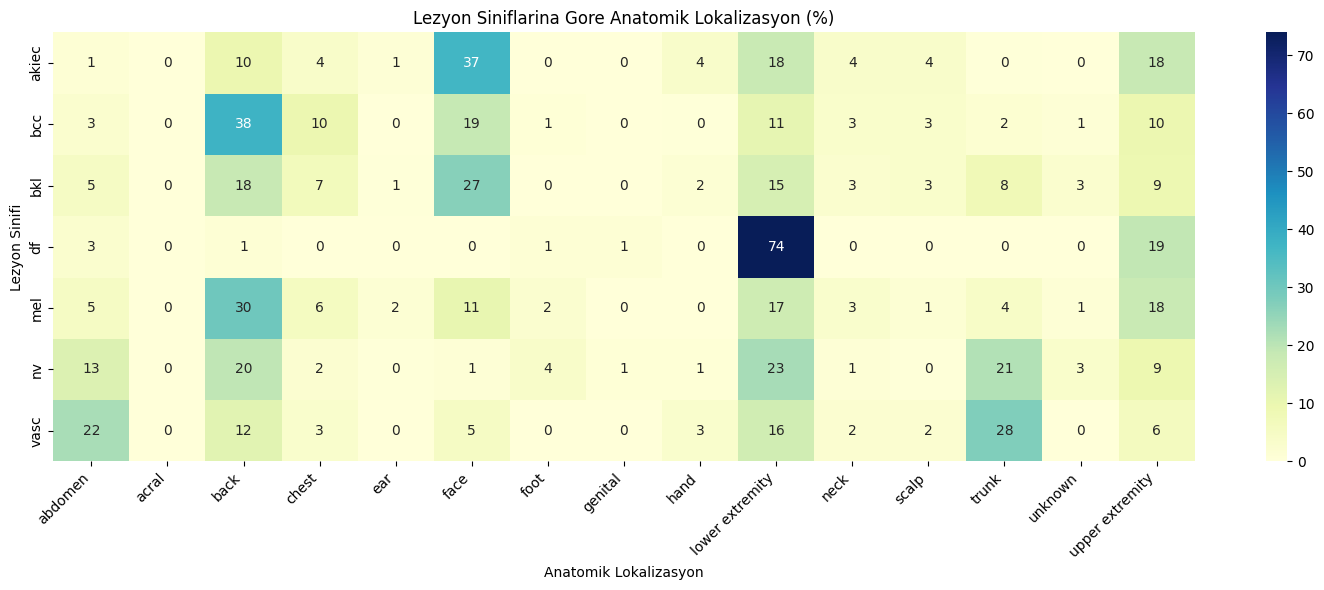

In [6]:

# 1. Ayni lezyona ait metadata tutarliligi
sutunlar = ["dx", "age", "sex", "localization"]

for sutun in sutunlar:
    farkli = df.groupby("lesion_id")[sutun].nunique(
        dropna=False
    )
    print(
        sutun,
        "- Tutarsiz lezyon sayisi:",
        (farkli > 1).sum()
    )

# 2. Lezyon duzeyinde veri
lesion_df = df.drop_duplicates("lesion_id").copy()

print("\nLezyon duzeyinde kayit sayisi:")
print(len(lesion_df))

print("\nLezyon duzeyinde sinif dagilimi (%):")
display(
    (lesion_df["dx"].value_counts(normalize=True) * 100)
    .round(2)
)

# 3. Bilinmeyen ve eksik metadata
print("\nEksik yas:", df["age"].isna().sum())
print("Bilinmeyen cinsiyet:",
      (df["sex"] == "unknown").sum())
print("Bilinmeyen lokalizasyon:",
      (df["localization"] == "unknown").sum())

# 4. Lokalizasyon ve sinif iliskisi
lok_tablo = pd.crosstab(
    lesion_df["dx"],
    lesion_df["localization"],
    normalize="index"
) * 100

plt.figure(figsize=(15, 6))
sns.heatmap(
    lok_tablo,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)
plt.title("Lezyon Siniflarina Gore Anatomik Lokalizasyon (%)")
plt.xlabel("Anatomik Lokalizasyon")
plt.ylabel("Lezyon Sinifi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("lokalizasyon_sinif.png", dpi=300)
plt.show()


In [7]:

# Lokalizasyonu tutarsiz olan lezyonlari bul
lok_sayisi = df.groupby("lesion_id")["localization"].nunique(
    dropna=False
)

tutarsiz_idler = lok_sayisi[lok_sayisi > 1].index

tutarsiz_kayitlar = df[
    df["lesion_id"].isin(tutarsiz_idler)
].sort_values(["lesion_id", "image_id"])

print("Tutarsiz lezyon sayisi:", len(tutarsiz_idler))

display(
    tutarsiz_kayitlar[
        ["lesion_id", "image_id", "dx",
         "age", "sex", "localization"]
    ]
)


Tutarsiz lezyon sayisi: 2


,lesion_id,image_id,dx,age,sex,localization
1211,HAM_0000871,ISIC_0025964,mel,40.0,female,chest
2014,HAM_0000871,ISIC_0026506,mel,40.0,female,trunk
1212,HAM_0000871,ISIC_0030623,mel,40.0,female,chest
1248,HAM_0001726,ISIC_0024367,mel,35.0,female,back
2008,HAM_0001726,ISIC_0024700,mel,35.0,female,trunk
1247,HAM_0001726,ISIC_0029281,mel,35.0,female,back


In [8]:

# Orijinal metadata korunur
df["localization_grouped"] = df["localization"].copy()

# Anatomik olarak iliskili bolgeleri birlestir
trunk_regions = ["chest", "back", "abdomen", "trunk"]

df.loc[
    df["localization"].isin(trunk_regions),
    "localization_grouped"
] = "trunk"

# Gruplama sonrasi tutarlilik kontrolu
grouped_counts = df.groupby("lesion_id")[
    "localization_grouped"
].nunique(dropna=False)

print(
    "Gruplama sonrasi tutarsiz lezyon sayisi:",
    (grouped_counts > 1).sum()
)

print("\nGruplanmis lokalizasyon dagilimi:")
display(df["localization_grouped"].value_counts())

print("\nIki lezyonun yeni lokalizasyonlari:")
display(
    df[df["lesion_id"].isin(
        ["HAM_0000871", "HAM_0001726"]
    )][
        ["lesion_id", "localization",
         "localization_grouped"]
    ]
)


Gruplama sonrasi tutarsiz lezyon sayisi: 0

Gruplanmis lokalizasyon dagilimi:


,count
localization_grouped,
trunk,5025
lower extremity,2077
upper extremity,1118
face,745
foot,319
unknown,234
neck,168
scalp,128
hand,90



Iki lezyonun yeni lokalizasyonlari:


,lesion_id,localization,localization_grouped
1211,HAM_0000871,chest,trunk
1212,HAM_0000871,chest,trunk
1247,HAM_0001726,back,trunk
1248,HAM_0001726,back,trunk
2008,HAM_0001726,trunk,trunk
2014,HAM_0000871,trunk,trunk


In [9]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Her lezyon icin tek kayit
lesion_table = df.groupby("lesion_id").agg(
    dx=("dx", "first"),
    image_count=("image_id", "count")
).reset_index()

# Lezyonlari siniflarini koruyarak ayir
train_lesions, temp_lesions = train_test_split(
    lesion_table,
    test_size=0.30,
    stratify=lesion_table["dx"],
    random_state=SEED
)

val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["dx"],
    random_state=SEED
)

# Lezyon ID'lerine gore goruntuleri ayir
train_df = df[
    df["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

val_df = df[
    df["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

test_df = df[
    df["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

# Veri sizintisi kontrolu
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("Lezyon bazli veri sizintisi: YOK")

# Bolme sonuclari
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(subset)} goruntu, "
        f"{subset['lesion_id'].nunique()} lezyon, "
        f"%{len(subset)/len(df)*100:.2f}"
    )

# Sinif dagilimlari
distribution = pd.DataFrame({
    "Tum veri": df["dx"].value_counts(normalize=True),
    "Train": train_df["dx"].value_counts(normalize=True),
    "Validation": val_df["dx"].value_counts(normalize=True),
    "Test": test_df["dx"].value_counts(normalize=True)
}).fillna(0) * 100

print("\nGoruntu bazli sinif dagilimi (%):")
display(distribution.round(2))

print("\nTest kumesindeki sinif sayilari:")
display(test_df["dx"].value_counts().sort_index())


Lezyon bazli veri sizintisi: YOK
Train: 6981 goruntu, 5229 lezyon, %69.71
Validation: 1532 goruntu, 1120 lezyon, %15.30
Test: 1502 goruntu, 1121 lezyon, %15.00

Goruntu bazli sinif dagilimi (%):


,Tum veri,Train,Validation,Test
dx,,,,
akiec,3.27,3.18,3.46,3.46
bcc,5.13,5.17,5.35,4.73
bkl,10.97,11.06,10.44,11.12
df,1.15,1.02,1.57,1.33
mel,11.11,11.07,11.29,11.12
nv,66.95,67.08,66.45,66.84
vasc,1.42,1.42,1.44,1.40



Test kumesindeki sinif sayilari:


,count
dx,
akiec,52
bcc,71
bkl,167
df,20
mel,167
nv,1004
vasc,21


In [10]:

import os
import pandas as pd

# Bolme bilgilerini tek tabloda birlestir
train_save = train_df[
    ["lesion_id", "image_id", "dx"]
].copy()
train_save["split"] = "train"

val_save = val_df[
    ["lesion_id", "image_id", "dx"]
].copy()
val_save["split"] = "validation"

test_save = test_df[
    ["lesion_id", "image_id", "dx"]
].copy()
test_save["split"] = "test"

splits_df = pd.concat(
    [train_save, val_save, test_save],
    ignore_index=True
)

splits_df = splits_df.sort_values(
    "image_id"
).reset_index(drop=True)

# Son guvenlik kontrolleri
assert len(splits_df) == 10015
assert splits_df["image_id"].is_unique

assert (
    splits_df.groupby("lesion_id")["split"].nunique() == 1
).all()

# Dosyayi kaydet
os.makedirs("/content/results", exist_ok=True)

output_path = "/content/results/ham10000_splits.csv"

splits_df.to_csv(output_path, index=False)

print("Dosya kaydedildi:", output_path)

print("\nBolme dagilimi:")
display(splits_df["split"].value_counts())

print("\nIlk 5 kayit:")
display(splits_df.head())


Dosya kaydedildi: /content/results/ham10000_splits.csv

Bolme dagilimi:


,count
split,
train,6981
validation,1532
test,1502



Ilk 5 kayit:


,lesion_id,image_id,dx,split
0,HAM_0000550,ISIC_0024306,nv,test
1,HAM_0003577,ISIC_0024307,nv,train
2,HAM_0001477,ISIC_0024308,nv,train
3,HAM_0000484,ISIC_0024309,nv,train
4,HAM_0003350,ISIC_0024310,mel,validation


In [11]:

from google.colab import files

files.download(
    "/content/results/ham10000_splits.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>